In [21]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

In [9]:
#dataset
layers = tf.keras.layers
df = pd.read_csv("creditcard.csv")
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [16]:
#split and scaling
X,y = df.drop(columns="Class").values.astype("float32"), df["Class"].values
Xtr,Xte,ytr,yte = train_test_split(X,y,test_size=0.2,stratify=y,random_state=42)
scaler = StandardScaler().fit(Xtr[ytr==0])
Xtrn = scaler.transform(Xtr[ytr==0]) # normal only
Xtes = scaler.transform(Xte) # normal + fraud
print(Xtrn.shape, yte.sum(), len(yte))

(227451, 30) 98 56962


In [17]:
#layers
inp = keras.Input(shape=(30,))
x = layers.Dense(24,activation="relu")(inp)
x = layers.Dense(14,activation="relu")(x)
z = layers.Dense(7,activation="relu")(x)
x = layers.Dense(14,activation="relu")(z)
x = layers.Dense(24,activation="relu")(x)
out = layers.Dense(30,activation="linear")(x)
ae = keras.Model(inp,out)

ae.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)           │ (None, 30)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_14 (Dense)                     │ (None, 24)                  │             744 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_15 (Dense)                     │ (None, 14)                  │             350 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_16 (Dense)                     │ (None, 7)                   │             105 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_17 (Dense)                     │ (None, 14)                  │             112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_18 (Dense)                     │ (None, 24)                  │             360 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_19 (Dense)                     │ (None, 30)                  │             750 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,421 (9.46 KB)

 Trainable params: 2,421 (9.46 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
#compile
ae.compile(optimizer="adam",loss="mse",metrics=["mae"])
hist = ae.fit(Xtrn,Xtrn,epochs=20,batch_size=256,validation_split=0.1)

Epoch 1/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - loss: 0.9110 - mae: 0.6266 - val_loss: 0.5791 - val_mae: 0.5313
Epoch 2/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 977us/step - loss: 0.5654 - mae: 0.5166 - val_loss: 0.4990 - val_mae: 0.4883
Epoch 3/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 977us/step - loss: 0.5130 - mae: 0.4802 - val_loss: 0.4632 - val_mae: 0.4646
Epoch 4/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4738 - mae: 0.4578 - val_loss: 0.4255 - val_mae: 0.4414
Epoch 5/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4390 - mae: 0.4370 - val_loss: 0.4088 - val_mae: 0.4301
Epoch 6/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4162 - mae: 0.4244 - val_loss: 0.3853 - val_mae: 0.4155
Epoch 7/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 980us/step - loss: 0.3998 - mae: 0.4153 - val_loss: 0.3775 - val_mae: 0.4101
Epoch 8/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 961us/step - loss: 0.3923 - mae: 0.4104 - val_loss: 0.3575 - val_mae: 0.4057
Epoch 9/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 978us

In [20]:
#reconstruction error
err_train = np.mean((Xtrn - ae.predict(Xtrn))**2,axis=1)
err_test = np.mean((Xtes - ae.predict(Xtes))**2,axis=1)
threshold = err_train.mean() + 3 * err_train.std()
pred = (err_test > threshold).astype(int)
print(threshold, pred.sum(),len(pred))

7108/7108 ━━━━━━━━━━━━━━━━━━━━ 3s 425us/step
1781/1781 ━━━━━━━━━━━━━━━━━━━━ 1s 401us/step
2.051925092935562 365 56962


In [23]:
#evaluate
print(classification_report(yte,pred,target_names=["normal","anomaly"],digits=3))
print(confusion_matrix(yte,pred))
print(round(roc_auc_score(yte,err_test),4))

              precision    recall  f1-score   support

      normal      1.000     0.995     0.997     56864
     anomaly      0.219     0.816     0.346        98

    accuracy                          0.995     56962
   macro avg      0.609     0.906     0.671     56962
weighted avg      0.998     0.995     0.996     56962

[[56579   285]
 [   18    80]]
0.9337


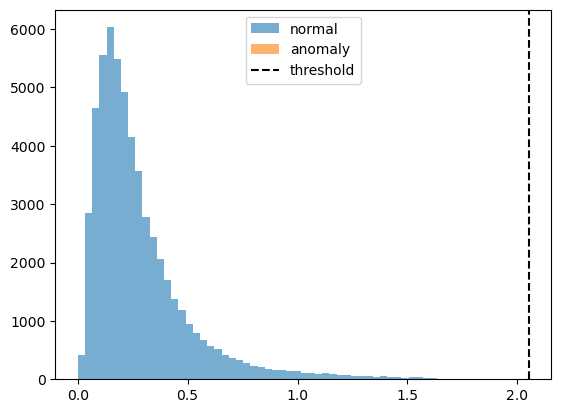

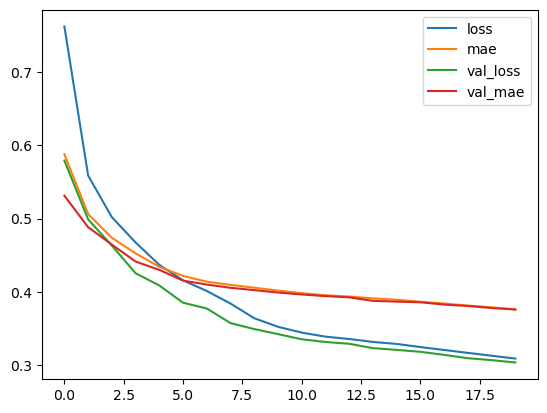

In [30]:
#plot
for k in (0,1):
    plt.hist(err_test[yte==k],50,range=(0,np.percentile(err_test,99)),alpha=0.6,label=["normal","anomaly"][k])
plt.axvline(threshold,color="k",ls="--",label="threshold")
plt.legend()
pd.DataFrame(hist.history).plot();
plt.show()

normal: error 0.122 -> ok
fraud : error 8.585 -> FRAUD | threshold 2.052
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


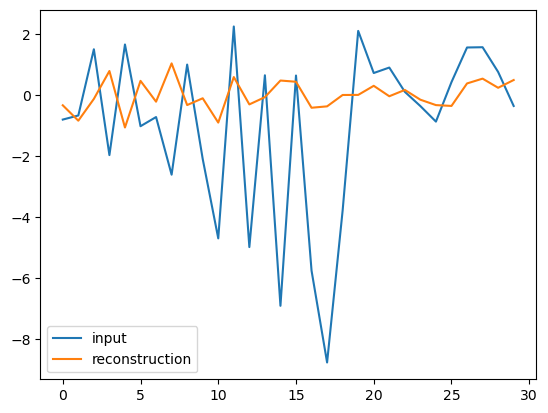

In [31]:
#one example
i = np.where(yte == 0)[0][0]                       # first normal transaction
j = np.where((yte == 1) & (pred == 1))[0][0]       # first fraud the model caught
print(f"normal: error {err_test[i]:.3f} -> {'FRAUD' if pred[i] else 'ok'}")
print(f"fraud : error {err_test[j]:.3f} -> {'FRAUD' if pred[j] else 'ok'} | threshold {threshold:.3f}")
plt.plot(Xtes[j], label="input"); plt.plot(ae.predict(Xtes[j:j+1])[0], label="reconstruction")
plt.legend(); plt.show()                           # the gap between the two lines is the error